# DataCopilot tutorial: check a real dataset before you train on it

You will use DataCopilot on **real photos** (COCO128) and a **real image model** (DINOv2-small), and every
result below was produced by actually running the commands: nothing is made up or hand-edited.

How to read this notebook: each code cell is followed by a short **What this shows** note in plain English.
The first run downloads about 7 MB of photos and about 90 MB of model weights; after that everything is cached.
Run the cells from top to bottom. The notebook can be re-run from the start at any time.

## 1. What DataCopilot is for

Computer-vision models learn from photos plus labels (for example, a rectangle drawn around every car), and mistakes in
those labels quietly make the model worse. DataCopilot reads a labelled dataset in any common format, checks it for
mistakes such as broken boxes, missing files, lopsided classes and the same picture hiding in both the training and the
test data, and converts it between formats while telling you exactly what a conversion could not carry over.
It runs on your own computer from the command line or from Python, and it can fail an automated build (a "CI job")
when a dataset is not good enough.

**About the data and its licence.** The photos come from COCO (train2017) through the COCO128 sample published by
Ultralytics. The COCO annotations are licensed CC BY 4.0, and each image keeps the licence of its original Flickr
owner. These notebooks download the sample at run time into a cache folder outside the repository and never
copy, commit or redistribute any image.

### Set-up

The next cell prepares a clean work folder (inside a cache folder outside the repository) and defines two small
helpers. `datacopilot(...)` runs a real DataCopilot command exactly as a terminal would and prints the command, its
output and its **exit code** (0 means success; anything else means failure). DataCopilot also writes technical log
lines (JSON) to the "error" stream; the helper hides them, and the notebook turns them down to errors, so you only see
the readable messages.

In [1]:
import hashlib
import json
import os
import shlex
import shutil
import subprocess
import sys
import tempfile
import time
import types
import urllib.request
import warnings
import zipfile
from pathlib import Path

DATA_URL = "https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128.zip"
KNOWN_SHA256 = "61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e"

# Where downloads are cached (outside the repository) and where this notebook works.
DATA = Path(
    os.environ.get("DATACOPILOT_NOTEBOOK_DATA")
    or Path(tempfile.gettempdir()) / "datacopilot-notebooks"
).resolve()
WORK = DATA / "work-tutorial"
shutil.rmtree(WORK, ignore_errors=True)  # start clean, so the notebook can be re-run from the top
WORK.mkdir(parents=True)
os.chdir(WORK)  # everything below uses paths relative to this folder

# Printing helper: hide the folders of this machine behind short placeholders.
_HIDE = [
    (str(p), name)
    for p, name in [
        (WORK, "<work>"),
        (WORK.resolve(), "<work>"),
        (DATA, "<data>"),
        (DATA.resolve(), "<data>"),
        (Path(tempfile.gettempdir()), "<tmp>"),
        (Path(tempfile.gettempdir()).resolve(), "<tmp>"),
        (Path.home(), "~"),
    ]
]
_HIDE.sort(key=lambda pair: -len(pair[0]))


def tidy(text):
    for real, placeholder in _HIDE:
        text = text.replace(real, placeholder)
    return text


class Done(types.SimpleNamespace):
    """What a command returned (shows nothing when it ends a cell)."""

    def _ipython_display_(self):
        pass


def datacopilot(*args, env=None, timed=False):
    """Run one `datacopilot` command like a terminal: show the command, what it prints and its exit code."""
    start = time.perf_counter()
    done = subprocess.run(  # noqa: S603  (our own command, no shell)
        [sys.executable, "-m", "datacopilot", *map(str, args)],
        capture_output=True,
        text=True,
        timeout=3600,
        env={**os.environ, "TQDM_DISABLE": "1", "HF_HUB_DISABLE_PROGRESS_BARS": "1", **(env or {})},
    )
    seconds = time.perf_counter() - start
    done.messages = [
        tidy(line) for line in done.stderr.splitlines() if line.strip() and not line.startswith("{")
    ]
    print("$ datacopilot " + " ".join(shlex.quote(str(a)) for a in args))
    for line in done.stdout.splitlines():
        print(tidy(line)[:240])
    for line in done.messages:
        print("[message]", line[:400])
    print(f"[exit code {done.returncode}" + (f", {seconds:.1f} s]" if timed else "]"))
    return Done(
        returncode=done.returncode,
        stdout=done.stdout,
        stderr=done.stderr,
        messages=done.messages,
        seconds=seconds,
    )


def latest_report(name="report.json"):
    """The report the last audit wrote next to us (JSON version)."""
    return json.loads(Path(name).read_text())


os.environ["DATACOPILOT_LOG_LEVEL"] = "ERROR"  # keep the technical JSON log lines out of this page
os.environ["TQDM_DISABLE"] = os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = (
    "1"  # no progress bars on this page
)
warnings.filterwarnings("ignore")
print("cache folder :", tidy(str(DATA)))
print("work folder  :", tidy(str(WORK)))
print("python       :", sys.version.split()[0])

cache folder : <data>
work folder  : <work>
python       : 3.13.9


**What this shows.** Every file this notebook creates lives in the work folder, and every path printed below is
relative to it. The cache folder is `<data>` and the work folder is `<work>` so that no real folder names appear on this page.

## 2. Check the installation with `datacopilot doctor`

`doctor` is the first thing to run when something looks wrong: it lists versions, the optional extras, the settings
and whether a GPU is visible. It never prints secrets.

In [2]:
datacopilot("--version")
datacopilot("doctor")

$ datacopilot --version
datacopilot 0.1.0
[exit code 0]


$ datacopilot doctor
ok
package: datacopilot 0.1.0 (dcp schema 1)
python: 3.13.9 on Darwin
dependencies: ok (click 8.5.0, jinja2 3.1.6, numpy 2.5.4, pyarrow 26.0.0, pydantic 2.14.1, structlog 26.1.0, typer 0.27.3)
extras: embed available
settings: ok (env=prod, log_level=ERROR, workers=12, hash_cache=true, ci=false, cache_key=unset)
cache: ~/.cache/datacopilot (writable, 2 files, 22852 bytes)
faiss: installed 1.15.1
gpu: tensor library 2.14.1, mps
plugins: formats=6, checks=7, embedders=4
[exit code 0]


**What this shows.** `ok` on the first line and exit code 0 mean the installation works. The line starting with
`extras: embed available` tells us the optional image-model support is installed, which section 9 needs.

## 3. Download the real photos and look at them

COCO128 is 128 real photographs with a label file per photo. The label format is "YOLO": one line per box with the
class number and the box position as fractions of the image size. The cell below downloads the zip file (once), prints its
fingerprint (a SHA-256 checksum, so you can tell you got the same file as everybody else) and unpacks it.

In [3]:
def fetch_coco128():
    """Download COCO128 once into the cache folder and return the path of the zip file."""
    DATA.mkdir(parents=True, exist_ok=True)
    target = DATA / "coco128.zip"
    if not target.exists():
        partial = target.with_suffix(".part")
        try:
            with urllib.request.urlopen(DATA_URL, timeout=60) as reply, open(partial, "wb") as out:
                shutil.copyfileobj(reply, out)
        except OSError as problem:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                "Could not download COCO128 (" + type(problem).__name__ + "). "
                "These notebooks need the network once to fetch about 7 MB from " + DATA_URL + ". "
                "Connect and run this cell again, or download that file yourself and save it as "
                "'coco128.zip' in the cache folder (set DATACOPILOT_NOTEBOOK_DATA to choose where it is)."
            ) from None
        partial.replace(target)
    return target


zip_path = fetch_coco128()
digest = hashlib.sha256(zip_path.read_bytes()).hexdigest()
print("file    :", zip_path.name, f"({zip_path.stat().st_size / 1e6:.1f} MB)")
print("sha256  :", digest)
print("matches the file this notebook was written against:", digest == KNOWN_SHA256)

raw = Path("raw")
with zipfile.ZipFile(zip_path) as archive:
    for member in archive.namelist():  # refuse any name that would land outside "raw"
        if not (raw / member).resolve().is_relative_to(raw.resolve()):
            raise RuntimeError("unsafe name in the archive: " + member)
    archive.extractall(raw)
print("images  :", len(list((raw / "coco128/images/train2017").glob("*.jpg"))))
print("labels  :", len(list((raw / "coco128/labels/train2017").glob("*.txt"))))

file    : coco128.zip (7.0 MB)
sha256  : 61e5e3028863d8ffc3b81d6a514603954889f0edd5e4b44c4ce60b2da99aeb8e
matches the file this notebook was written against: True
images  : 128
labels  : 128


**What this shows.** The download succeeded, the checksum is printed so the exact file is on record, and the archive
holds 128 photos with 128 label files. Nothing was downloaded into the repository.

COCO128 ships as one folder with no list of class names and no validation set, and DataCopilot's YOLO reader wants both.
So we arrange the files into the layout it expects: a `data.yaml` with the 80 official COCO class names, and every fifth
photo (sorted by name) goes into a `val` split for validation, the rest into `train`.

In [4]:
# COCO128 is one folder of 128 photos with no list of class names and no validation split, so we
# add both: the 80 official COCO class names, and every fifth photo (sorted by name) becomes "val".
NAMES = [
    n.replace("_", " ")
    for n in "person bicycle car motorcycle airplane bus train truck boat traffic_light fire_hydrant stop_sign parking_meter bench bird cat dog horse sheep cow elephant bear zebra giraffe backpack umbrella handbag tie suitcase frisbee skis snowboard sports_ball kite baseball_bat baseball_glove skateboard surfboard tennis_racket bottle wine_glass cup fork knife spoon bowl banana apple sandwich orange broccoli carrot hot_dog pizza donut cake chair couch potted_plant bed dining_table toilet tv laptop mouse remote keyboard cell_phone microwave oven toaster sink refrigerator book clock vase scissors teddy_bear hair_drier toothbrush".split()
]
if len(NAMES) != 80:
    raise ValueError("expected the 80 COCO class names")


def build_yolo_layout(target="coco128"):
    """Copy the raw COCO128 files into the folder layout DataCopilot's YOLO reader expects."""
    target = Path(target)
    source = raw / "coco128"
    photos = sorted((source / "images/train2017").glob("*.jpg"))
    for number, photo in enumerate(photos):
        split = "val" if number % 5 == 4 else "train"
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        shutil.copy(photo, target / "images" / split / photo.name)
        label = source / "labels/train2017" / (photo.stem + ".txt")
        if label.exists():
            shutil.copy(label, target / "labels" / split / label.name)
    names = ", ".join(json.dumps(n) for n in NAMES)
    (target / "data.yaml").write_text(
        f"path: .\ntrain: images/train\nval: images/val\nnc: 80\nnames: [{names}]\n"
    )
    return target


build_yolo_layout("coco128")
print(sorted(p.name for p in Path("coco128").iterdir()))
print("train photos:", len(list(Path("coco128/images/train").glob("*.jpg"))))
print("val photos  :", len(list(Path("coco128/images/val").glob("*.jpg"))))

['data.yaml', 'images', 'labels']
train photos: 103
val photos  : 25


**What this shows.** The dataset now has the folder layout `images/<split>/` and `labels/<split>/` plus a `data.yaml`, with
103 photos to train on and 25 to validate on. Splitting by every fifth file is arbitrary but repeatable.

Let's look at six photos with their boxes drawn on top. We read them with `dc.load`, which reads a dataset into memory
without writing anything.

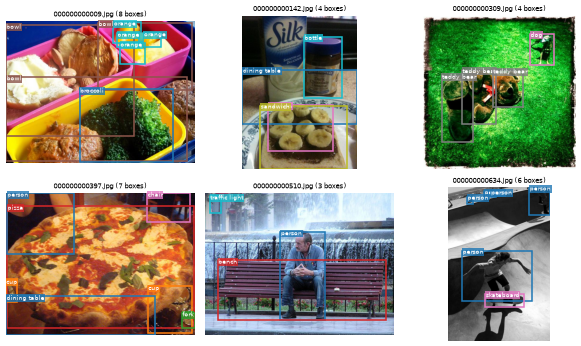

In [5]:
from collections import Counter, defaultdict

import matplotlib
import matplotlib.pyplot as plt
from PIL import Image as PILImage

import datacopilot as dc

plt.rcParams["figure.dpi"] = 55
source = dc.load("coco128", format="yolo")
class_name = {c.id: c.name for c in source.categories}
boxes_of = defaultdict(list)
for ann in source.annotations:
    boxes_of[ann.image_id].append(ann)

# six photos with a handful of boxes each, spread over the sorted list so they look different
candidates = [
    i
    for i in sorted(source.images, key=lambda i: i.file_path)
    if 3 <= len(boxes_of[i.image_id]) <= 8
]
chosen = candidates[:: max(1, len(candidates) // 6)][:6]

fig, axes = plt.subplots(2, 3, figsize=(11, 6.4))
palette = matplotlib.colormaps["tab10"]
for ax, image in zip(axes.flat, chosen, strict=False):
    ax.imshow(PILImage.open(image.file_path))
    for ann in boxes_of[image.image_id]:
        x1, y1, x2, y2 = ann.bbox_xyxy_abs
        colour = palette(ann.category_id % 10)
        ax.add_patch(
            plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=colour, linewidth=2)
        )
        ax.text(
            x1 + 2,
            y1 + 12,
            class_name[ann.category_id],
            fontsize=8,
            color="white",
            bbox=dict(facecolor=colour, alpha=0.8, pad=1, edgecolor="none"),
        )
    ax.set_title(
        f"{Path(image.file_path).name} ({len(boxes_of[image.image_id])} boxes)", fontsize=9
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

**What this shows.** These are ordinary everyday photographs, and a "box" is just a rectangle (in pixels) with a class
name. DataCopilot's job is to check thousands of such rectangles automatically instead of by eye.

## 4. Ingest: turn the folder into a versioned dataset

`ingest` reads the dataset, checks that every rule of the data model holds (for instance, that every box lies inside its
photo) and writes a `.dcp` folder. It prints the **version id**: a fingerprint of the content, so the same data always
gets the same id. Write it next to your training run and you can always tell which data a model was trained on.

In [6]:
ingest = datacopilot("ingest", "coco128", "--format", "yolo", "-o", "coco128.dcp")

$ datacopilot ingest coco128 --format yolo -o coco128.dcp
0bce211539be183579ee59d8f6b942e7
[exit code 0]


**What this shows.** Exit code 0 and one line: the 32-character version id. The photos are not copied; the `.dcp` folder
only records tables of images, boxes and classes.

Now the summary of what is inside, using the Python API (`dc.load`):

In [7]:
ds = dc.load("coco128.dcp")
m = ds.manifest
name_of = {c.id: c.name for c in ds.categories}
per_class = Counter(name_of[a.category_id] for a in ds.annotations)
boxes_per_image = Counter(a.image_id for a in ds.annotations)
split_of = {i.image_id: i.split for i in ds.images}
print("version id   :", m.version)
print("task         :", m.task)
print("images       :", m.image_count, dict(Counter(split_of.values())))
print(
    "boxes        :",
    m.annotation_count,
    dict(Counter(split_of[a.image_id] for a in ds.annotations)),
)
print("class names  :", len(name_of), "defined,", len(per_class), "actually used")
print("images with no box:", sum(1 for i in ds.images if i.image_id not in boxes_per_image))
print(
    "boxes per image   : most",
    max(boxes_per_image.values()),
    "| typical",
    sorted(boxes_per_image.values())[len(boxes_per_image) // 2],
)
print()
print("boxes per class (15 most common):")
for name, n in per_class.most_common(15):
    print(f"  {name:<15}{n:>4}  " + "#" * max(1, n // 5))
print("classes that appear only once:", sum(1 for n in per_class.values() if n == 1))

version id   : 0bce211539be183579ee59d8f6b942e7
task         : detection
images       : 128 {'train': 103, 'val': 25}
boxes        : 929 {'train': 817, 'val': 112}
class names  : 80 defined, 71 actually used
images with no box: 2
boxes per image   : most 42 | typical 4

boxes per class (15 most common):
  person          254  ##################################################
  car              46  #########
  cup              36  #######
  chair            35  #######
  book             29  #####
  bowl             28  #####
  carrot           24  ####
  spoon            22  ####
  teddy bear       21  ####
  handbag          19  ###
  umbrella         18  ###
  bottle           18  ###
  elephant         17  ###
  knife            16  ###
  bird             16  ###
classes that appear only once: 4


**What this shows.** COCO128 has 128 photos with 929 boxes in 71 of the 80 class names. The class `person` alone has 254 boxes,
while a few classes appear only once: this lopsidedness is real and is what the audit reports on next.

## 5. Audit the real data as it is

`audit` runs the checks and writes `report.html` (to read), `report.json` (for programs) and a third report for
code-scanning tools. The built-in checks look at the files (are they readable, are any identical?), the class balance and
the boxes. `--no-hash-cache` switches off an optional speed-up cache; it is what a CI job should use.

In [8]:
audit = datacopilot("audit", "coco128.dcp", "--no-hash-cache")

$ datacopilot audit coco128.dcp --no-hash-cache
passed critical=0 warn=12 info=1 run_id=bf136ca8-23b4-489d-a32e-ec1fe2d61050
[exit code 0]


**What this shows.** `passed` means no *critical* finding, so the default gate (which fails only on critical findings) lets the
dataset through. There are still warnings, and real data nearly always has some. The next cells explain each one.

In [9]:
report = latest_report()
file_of = {i.image_id: Path(i.file_path).name for i in ds.images}
ann_of = {a.ann_id: a for a in ds.annotations}
counts = Counter((f["check"], f["payload"]["rule"], f["severity"]) for f in report["findings"])
print(f"{'check':<11}{'what was found':<24}{'level':<6}  count")
for (check, rule, level), n in sorted(counts.items()):
    print(f"{check:<11}{rule:<24}{level:<6}  {n}")
print("\ntotals:", report["counts"])

check      what was found          level   count
boxes      conflicting_class       WARN    1
boxes      tiny_box                WARN    7
imbalance  class_missing_in_split  WARN    2
imbalance  class_unused            INFO    1
imbalance  long_tail               WARN    2

totals: {'critical': 0, 'info': 1, 'warn': 12}


**What this shows.** A one-glance table of every finding: two kinds of box problem (`tiny_box`, `conflicting_class`) and three kinds of
class-balance problem (`long_tail`, `class_missing_in_split`, `class_unused`). Warnings need a human look; they are not proof of an error.

In [10]:
print("TINY BOXES (smaller than 1/10,000 of the photo, or thinner than 2 pixels)")
for f in report["findings"]:
    if f["payload"]["rule"] == "tiny_box":
        ann = ann_of[f["ann_id"]]
        p = f["payload"]
        print(
            f"  {file_of[f['image_id']]:<19}{name_of[ann.category_id]:<14}{p['width']:.1f} x {p['height']:.1f} px"
        )
print("\nCONFLICTING CLASSES (two boxes on nearly the same spot with different classes)")
for f in report["findings"]:
    if f["payload"]["rule"] == "conflicting_class":
        p = f["payload"]
        print(
            f"  {file_of[f['image_id']]}: '{name_of[p['category_id']]}' and '{name_of[p['other_category_id']]}', overlap {p['iou']:.2f}"
        )

TINY BOXES (smaller than 1/10,000 of the photo, or thinner than 2 pixels)
  000000000531.jpg   tennis racket 4.3 x 4.2 px
  000000000531.jpg   sports ball   1.9 x 2.8 px
  000000000540.jpg   car           5.7 x 4.4 px
  000000000540.jpg   traffic light 1.8 x 1.9 px
  000000000257.jpg   traffic light 4.9 x 4.3 px
  000000000257.jpg   handbag       6.1 x 4.6 px
  000000000542.jpg   tie           1.2 x 10.1 px

CONFLICTING CLASSES (two boxes on nearly the same spot with different classes)
  000000000536.jpg: 'person' and 'chair', overlap 0.92


**What this shows.** The tiny boxes are real small objects far away in the photo (a few pixels wide), and the conflicting pair is two
labels on almost the same rectangle. Both are worth one look by eye; neither is automatically wrong, because real COCO photos
contain distant objects and things that overlap, such as a person sitting on a chair.

In [11]:
for f in report["findings"]:
    p = f["payload"]
    if p["rule"] == "long_tail":
        head = ", ".join(f"{h['name']} {h['count']}" for h in p["head"][:3])
        tail = ", ".join(f"{t['name']} {t['count']}" for t in p["tail"][:3])
        print(
            f"{p['split']:<5} most common / rarest class = {p['ratio']:.0f} to 1 | effective classes {p['effective_classes']:.1f} of {p['classes_present']}"
        )
        print(f"      most common: {head}   rarest: {tail}")
    elif p["rule"] == "class_missing_in_split":
        print(
            f"{p['split']:<5} has no box at all for {p['count']} classes that exist elsewhere in the dataset"
        )
    elif p["rule"] == "class_unused":
        print(f"      {p['count']} of the {len(name_of)} class names are never used anywhere")

train has no box at all for 2 classes that exist elsewhere in the dataset
train most common / rarest class = 234 to 1 | effective classes 28.1 of 69
      most common: person 234, cup 35, chair 32   rarest: skis 1, banana 1, donut 1
val   has no box at all for 41 classes that exist elsewhere in the dataset
val   most common / rarest class = 20 to 1 | effective classes 19.0 of 30
      most common: person 20, car 15, donut 13   rarest: tennis racket 1, cup 1, broccoli 1
      9 of the 80 class names are never used anywhere


**What this shows.** "Effective classes" is a fairness score: the number of equally common classes that would give the same spread.
Here one class (`person`) alone holds about a quarter of all boxes, the validation split has no example of most of the classes, and 9 class names are
never used. With only 128 photos this is expected, but a model trained on it would be good at people and unreliable on the rare classes.

In [12]:
def touches_edge(ann, image):
    x1, y1, x2, y2 = ann.bbox_xyxy_abs
    return x1 <= 1 or y1 <= 1 or x2 >= image.width - 1 or y2 >= image.height - 1


image_of = {i.image_id: i for i in ds.images}
edge = [a for a in ds.annotations if touches_edge(a, image_of[a.image_id])]
print(f"{len(edge)} of {len(ds.annotations)} boxes touch the edge of their photo (within 1 pixel)")
by_class = Counter(name_of[a.category_id] for a in edge).most_common(4)
print("most often:", ", ".join(f"{n} {c}" for n, c in by_class))
print(
    "DataCopilot findings about this:",
    sum(1 for f in report["findings"] if f["payload"]["rule"] in ("out_of_bounds", "zero_area")),
)

144 of 929 boxes touch the edge of their photo (within 1 pixel)
most often: person 42, dining table 10, chair 8, cup 7
DataCopilot findings about this: 0


**What this shows.** Many boxes touch a photo's border because the photographer cut the object off. That is normal and legal, so DataCopilot
does not warn about it; it only warns (as `out_of_bounds`) when a box reaches *outside* the photo, which would be a real error and which
this dataset does not have. The zero in the last line confirms that.

## 6. Convert to other formats and count what is lost

Labelling tools and training libraries each prefer a different file format. `export` writes the same dataset as COCO, Pascal VOC,
CVAT or Label Studio files. Every value the target format has no place for is **counted** ("dropped"), and rows that could not be
written at all are counted as "skipped": nothing is lost silently.

In [13]:
FORMATS = ["coco", "voc", "cvat_xml", "label_studio", "yolo"]
conversion = {}
for fmt in FORMATS:
    conversion[fmt] = dc.export(ds, fmt, f"export_{fmt}")
print(f"{'format':<14}{'rows written':>12}   lost values (dropped)            rows skipped")
for fmt, r in conversion.items():
    print(
        f"{fmt:<14}{r.rows_written:>12}   {str(r.dropped or 'nothing'):<32} {r.skipped or 'none'}"
    )

format        rows written   lost values (dropped)            rows skipped
coco                  1057   nothing                          none
voc                   1057   nothing                          none
cvat_xml              1057   nothing                          none
label_studio          1057   {'categories.id': 69, 'categories.unused': 9} none
yolo                  1057   nothing                          none


**What this shows.** COCO, VOC, CVAT and YOLO carry everything this dataset has, so their loss is empty. Label Studio has no list of
class numbers, so it cannot keep the class ids (`categories.id`) or the classes nobody uses (`categories.unused`). That is exactly the
kind of thing you want to know before converting.

A loss count is only a promise; here is the proof. We read each exported folder back and compare it with the original: same photos,
same split, same class names, and every box in the same place (we allow 0.001 pixel, because file formats print numbers with
limited digits).

In [14]:
def boxes_by_group(data):
    names = {c.id: c.name for c in data.categories}
    groups = defaultdict(list)
    for a in data.annotations:
        groups[(a.image_id, names[a.category_id])].append(a.bbox_xyxy_abs)
    return {k: sorted(v) for k, v in groups.items()}


original = boxes_by_group(ds)
original_images = {i.image_id: i.split for i in ds.images}
used_names = {name_of[a.category_id] for a in ds.annotations}
print(
    f"{'format':<14}{'same photos+split':<19}{'class names kept':<18}{'same boxes':<12}largest box change"
)
for fmt in FORMATS:
    back = dc.load(f"export_{fmt}", format=fmt)
    again = boxes_by_group(back)
    same_boxes = again.keys() == original.keys() and all(
        len(again[k]) == len(original[k]) for k in original
    )
    worst = max(
        (
            abs(p - q)
            for k in original
            for u, v in zip(original[k], again[k], strict=False)
            for p, q in zip(u, v, strict=True)
        ),
        default=0.0,
    )
    same_photos = {i.image_id: i.split for i in back.images} == original_images
    kept = f"{len(back.categories)} of {len(ds.categories)}"
    print(
        f"{fmt:<14}{str(same_photos):<19}{kept:<18}{str(same_boxes and worst < 1e-3):<12}{worst:.1e} px"
    )

format        same photos+split  class names kept  same boxes  largest box change
coco          True               80 of 80          True        5.7e-14 px
voc           True               80 of 80          True        0.0e+00 px


cvat_xml      True               80 of 80          True        0.0e+00 px


label_studio  True               71 of 80          True        5.0e-07 px
yolo          True               80 of 80          True        3.2e-05 px


**What this shows.** For every format the same 128 photos come back in the same splits, with every box in the same place: the largest movement is
0.00003 pixel, a rounding effect of the YOLO text files. So "lossless" really means nothing changed. The one visible difference is Label Studio, which
keeps only the 71 class names that boxes use, exactly as its loss count announced.

Real pipelines often want to **refuse** any loss. `--strict` does that: the export stops before writing anything.

In [15]:
datacopilot("export", "coco128.dcp", "--format", "coco", "-o", "strict_coco", "--strict")
datacopilot(
    "export", "coco128.dcp", "--format", "label_studio", "-o", "strict_label_studio", "--strict"
)
print("strict_label_studio written:", Path("strict_label_studio").exists())

$ datacopilot export coco128.dcp --format coco -o strict_coco --strict
strict_coco
[exit code 0]


$ datacopilot export coco128.dcp --format label_studio -o strict_label_studio --strict
[message] error: conversion dcp -> label_studio is lossy: categories.id=69, categories.unused=9
[exit code 1]
strict_label_studio written: False


**What this shows.** The lossless conversion passes with exit code 0. The lossy one fails with exit code 1, prints the exact loss counts and writes
nothing (the last line prints `False`).

## 7. Make a classification dataset by cropping the real boxes

A detector answers "where?"; a classifier only answers "what?". If you want the second, you can cut every box out of its photo and put
the crops into one folder per class: the "ImageFolder" layout that most training libraries understand. We skip boxes thinner than
32 pixels (too small to recognise) and shrink the crops so their longest side is at most 128 pixels.

In [16]:
crops = Path("crops")
kept = too_small = 0
for image in sorted(ds.images, key=lambda i: i.file_path):
    wanted = sorted(
        (a for a in ds.annotations if a.image_id == image.image_id), key=lambda a: a.ann_id
    )
    if not wanted:
        continue
    with PILImage.open(image.file_path) as photo:
        photo = photo.convert("RGB")
        for n, ann in enumerate(wanted):
            x1, y1, x2, y2 = (round(v) for v in ann.bbox_xyxy_abs)
            if min(x2 - x1, y2 - y1) < 32:
                too_small += 1
                continue
            piece = photo.crop((x1, y1, x2, y2))
            piece.thumbnail((128, 128))
            folder = crops / image.split / name_of[ann.category_id]
            folder.mkdir(parents=True, exist_ok=True)
            piece.save(folder / f"{Path(image.file_path).stem}_{n}.jpg", quality=90)
            kept += 1
print(f"crops written: {kept}   boxes skipped as too small: {too_small}")
print(
    "folders:",
    sorted(p.name for p in crops.iterdir()),
    "->",
    len(list(crops.glob("*/*"))),
    "class folders in total",
)

crops written: 514   boxes skipped as too small: 415
folders: ['train', 'val'] -> 95 class folders in total


**What this shows.** About half of the 929 boxes are big enough to be useful crops. The folder tree is `crops/<split>/<class>/<picture>.jpg`, and we
did not need any label file: the folder name is the label.

In [17]:
datacopilot("ingest", "crops", "--format", "imagefolder", "-o", "crops.dcp")
datacopilot("audit", "crops.dcp", "--no-hash-cache")
crop_report = latest_report()
crop_ds = dc.load("crops.dcp")
crop_names = {c.id: c.name for c in crop_ds.categories}
crop_counts = Counter(crop_names[a.category_id] for a in crop_ds.annotations)
print("task:", crop_ds.manifest.task, "| pictures:", crop_ds.manifest.image_count)
print(
    "most common:",
    crop_counts.most_common(3),
    "| rarest:",
    sorted(crop_counts.items(), key=lambda kv: kv[1])[:3],
)
for f in crop_report["findings"]:
    p = f["payload"]
    if p["rule"] == "long_tail":
        print(
            f"{p['split']}: imbalance ratio {p['ratio']:.0f} to 1, effective classes {p['effective_classes']:.1f} of {p['classes_present']}"
        )

$ datacopilot ingest crops --format imagefolder -o crops.dcp
a0f5d2876dff4e77fc1866b0d0593fb5
[exit code 0]


$ datacopilot audit crops.dcp --no-hash-cache
passed critical=0 warn=4 info=0 run_id=26a8eb48-48ef-46e9-96d5-621602ce36f2
[exit code 0]
task: classification | pictures: 514
most common: [('person', 143), ('bowl', 19), ('chair', 19)] | rarest: [('banana', 1), ('baseball glove', 1), ('bear', 1)]
train: imbalance ratio 125 to 1, effective classes 28.1 of 66
val: imbalance ratio 18 to 1, effective classes 17.6 of 29


**What this shows.** The same audit now works on a classification dataset and reports the same class lopsidedness, this time as a
hard number: the most common class (`person`) has well over a hundred times more pictures than the rarest ones. A classifier trained on this
would simply learn to answer "person".

## 8. The CI idea: let the audit stop a bad dataset automatically

"CI" (continuous integration) means a robot that checks every change. `--fail-on` tells `audit` which findings are bad enough to fail:
`critical` (the default) or `warn` (anything at least a warning). The robot only needs the **exit code**.

In [18]:
datacopilot("audit", "coco128.dcp", "--no-hash-cache", "--fail-on", "critical")
datacopilot("audit", "coco128.dcp", "--no-hash-cache", "--fail-on", "warn")
datacopilot("audit", "coco128.dcp", "--no-hash-cache", "--fail-on", "none")

$ datacopilot audit coco128.dcp --no-hash-cache --fail-on critical
passed critical=0 warn=12 info=1 run_id=3a50bd49-ee60-4c3a-b144-1d662488158a
[exit code 0]


$ datacopilot audit coco128.dcp --no-hash-cache --fail-on warn
failed critical=0 warn=12 info=1 run_id=a33dac1c-e8aa-4e37-aa00-f8d94ad844b4
[exit code 1]


$ datacopilot audit coco128.dcp --no-hash-cache --fail-on none
passed critical=0 warn=12 info=1 run_id=4cb8787e-face-4a00-a5b8-b96a7507ea9a
[exit code 0]


**What this shows.** The same dataset passes a "critical only" gate (exit 0) and fails a "warnings too" gate (exit 1). You choose how strict to be, and
`--fail-on none` just reports without ever failing.

## 9. Look-alike images with a real model: DINOv2-small

Two photos can be the same picture and still be different files (re-saved, resized, compressed), so comparing file bytes cannot find them.
An **embedding** model turns each photo into a list of numbers (a "vector") such that similar-looking photos get similar vectors. DataCopilot
uses a pinned, licence-checked copy of DINOv2-small. First the licence check, then the model's identity card from DataCopilot's registry:

In [19]:
from datacopilot.models.registry import get_model

card = get_model(
    "dinov2_small", {"Apache-2.0", "MIT", "BSD-3-Clause"}
)  # raises an error if the licence is not allowed
print("model    :", card.model_id, "from", card.repo)
print("licence  :", card.license, "(allowed list: Apache-2.0, MIT, BSD-3-Clause)")
print("revision :", card.revision, "(pinned: the exact version of the weights)")
print("vector   :", card.dims, "numbers per photo")
print("weights  :", {k: v[:16] + "..." for k, v in card.weights_sha256.items()})

model    : dinov2_small from facebook/dinov2-small
licence  : Apache-2.0 (allowed list: Apache-2.0, MIT, BSD-3-Clause)
revision : ed25f3a31f01632728cabb09d1542f84ab7b0056 (pinned: the exact version of the weights)
vector   : 384 numbers per photo
weights  : {'model.safetensors': 'ae1e99fcefd534ed...'}


**What this shows.** The licence is checked before anything is downloaded, the model version is pinned to one exact commit, and the downloaded weights are
verified against the checksums written here. You never get "whatever the website serves today".

In [20]:
embed = datacopilot("embed", "coco128.dcp", "--embedder", "dinov2_small", timed=True)

$ datacopilot embed coco128.dcp --embedder dinov2_small
embedded=128 total=128 cached=0 missing=0 model=dinov2_small@ed25f3a31f01 run_id=05479e56-fcef-4409-9025-de20eb78ea04
[exit code 0, 4.8 s]


**What this shows.** All 128 photos were turned into vectors by the real model on this computer's processor (the first run also downloads the weights, so it takes longer).
The vectors are stored inside the dataset folder, so later audits reuse them instead of recomputing.

To look at the vectors ourselves we call the model directly and measure how similar two photos are (cosine similarity: 1.0 means pointing the same way, 0 means
unrelated). Then we pick two query photos and show their 5 nearest neighbours.

embedded 128 photos into 384 numbers each in 4.2 s


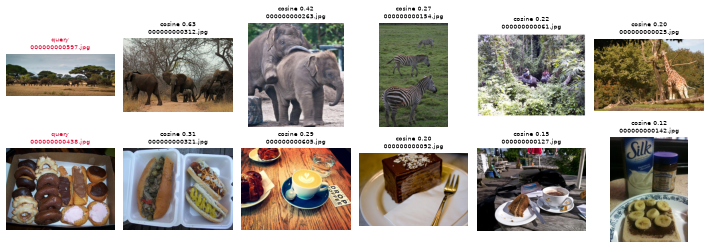

In [21]:
import contextlib
import io

import numpy as np

from datacopilot.embed.registry import get_embedder

t0 = time.perf_counter()
order = sorted(ds.images, key=lambda i: i.file_path)
blobs = [Path(i.file_path).read_bytes() for i in order]
with contextlib.redirect_stderr(io.StringIO()):  # the model library prints loading chatter; hide it
    embedder = get_embedder("dinov2_small", frozenset({"Apache-2.0", "MIT", "BSD-3-Clause"}))
    vectors = np.concatenate([embedder.embed(blobs[k : k + 32]) for k in range(0, len(blobs), 32)])
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)
similarity = vectors @ vectors.T
np.fill_diagonal(similarity, -1)  # a photo is not its own neighbour
print(
    "embedded",
    len(order),
    "photos into",
    vectors.shape[1],
    "numbers each in",
    f"{time.perf_counter() - t0:.1f} s",
)


def most_boxes_of(class_label):
    scores = Counter(a.image_id for a in ds.annotations if name_of[a.category_id] == class_label)
    return next(k for k, i in enumerate(order) if i.image_id == scores.most_common(1)[0][0])


queries = [most_boxes_of("elephant"), most_boxes_of("donut")]
fig, axes = plt.subplots(2, 6, figsize=(13, 4.6))
for row, q in zip(axes, queries, strict=True):
    neighbours = np.argsort(-similarity[q])[:5]
    for ax, k in zip(row, [q, *neighbours], strict=True):
        ax.imshow(PILImage.open(order[k].file_path))
        ax.axis("off")
        label = "query" if k == q else f"cosine {similarity[q, k]:.2f}"
        ax.set_title(
            f"{label}\n{Path(order[k].file_path).name}",
            fontsize=8,
            color="crimson" if k == q else "black",
        )
plt.tight_layout()
plt.show()

**What this shows.** Each row starts with a query photo (red title) followed by the five photos the model thinks look most like it, best first. They share a subject and
setting (elephants with elephants, donuts with food) although no label was used: the model compares pictures, not tags. The similarity numbers
are the cosine scores DataCopilot's near-duplicate and leakage checks use.

### The clean dataset passes; a planted leak does not

"Leakage" means the same picture sits in both the training and the validation data: the model has then seen the exam questions and its validation score
is too good to be true. First, the clean dataset with the leakage gate switched on (`--fail-on leakage`):

In [22]:
clean = datacopilot(
    "audit",
    "coco128.dcp",
    "--no-hash-cache",
    "--embedder",
    "dinov2_small",
    "--fail-on",
    "leakage",
    timed=True,
)
clean_report = latest_report()
model_findings = [
    f for f in clean_report["findings"] if f["check"] in ("near_duplicates", "leakage", "outliers")
]
print(
    "near-duplicate or leakage findings:",
    sum(1 for f in model_findings if f["check"] != "outliers"),
)
for f in model_findings:
    print("note:", f["check"], f["severity"], f["payload"]["rule"], "-", f["payload"]["count"])

$ datacopilot audit coco128.dcp --no-hash-cache --embedder dinov2_small --fail-on leakage
passed critical=0 warn=12 info=3 run_id=949b8c3f-cdff-4392-8d04-67a98c400dbd
[exit code 0, 3.4 s]
near-duplicate or leakage findings: 0
note: outliers INFO classes_skipped - 39
note: outliers INFO images_without_class - 2


**What this shows.** The clean dataset passes (exit code 0): the model found no near-duplicate pair and no leakage between train and validation. The
`outliers` lines are only informational notes: classes with fewer than 8 photos are skipped, and some photos have no class to compare against.

Now we plant a **real leak** on purpose. We take three photos from the training split, re-save each as a much lower-quality JPEG (so the bytes are different but the picture is
the same) and put the copies into the validation split under new names, with their labels.

In [23]:
shutil.copytree("coco128", "coco128_leaky")
train_photos = sorted(Path("coco128_leaky/images/train").glob("*.jpg"))
originals = [train_photos[10], train_photos[40], train_photos[70]]
planted = {}
for n, original_photo in enumerate(originals):
    copy_name = f"leak_{n}.jpg"
    with PILImage.open(original_photo) as photo:
        photo.save(Path("coco128_leaky/images/val") / copy_name, quality=35)
    shutil.copy(
        Path("coco128_leaky/labels/train") / (original_photo.stem + ".txt"),
        Path("coco128_leaky/labels/val") / f"leak_{n}.txt",
    )
    planted[copy_name] = original_photo.name
    print(
        f"planted {copy_name:<11} = {original_photo.name} at quality 35 "
        f"({original_photo.stat().st_size // 1024} KB -> {(Path('coco128_leaky/images/val') / copy_name).stat().st_size // 1024} KB)"
    )
datacopilot("ingest", "coco128_leaky", "--format", "yolo", "-o", "coco128_leaky.dcp")

planted leak_0.jpg  = 000000000074.jpg at quality 35 (46 KB -> 24 KB)
planted leak_1.jpg  = 000000000309.jpg at quality 35 (111 KB -> 57 KB)
planted leak_2.jpg  = 000000000486.jpg at quality 35 (55 KB -> 29 KB)


$ datacopilot ingest coco128_leaky --format yolo -o coco128_leaky.dcp
f22c2657df172f91d5158fa412302352
[exit code 0]


**What this shows.** The leaky dataset has three extra validation photos that are visibly the same as three training photos but are smaller, different files. It
ingests without complaint, because byte for byte they are not identical.

In [24]:
print("-- the normal audit (compares file bytes only) --")
datacopilot("audit", "coco128_leaky.dcp", "--no-hash-cache")
print()
print("-- the audit with the model, gated on leakage --")
leaky = datacopilot(
    "audit",
    "coco128_leaky.dcp",
    "--no-hash-cache",
    "--embedder",
    "dinov2_small",
    "--fail-on",
    "leakage",
    timed=True,
)
leak_report = latest_report()
found = {}
for f in leak_report["findings"]:
    if f["check"] == "leakage" and f["payload"]["rule"] == "cross_split_near_duplicate":
        members = {m["file_name"]: m["split"] for m in f["payload"]["members"]}
        print(
            f"  leak: {sorted(members)} cosine {f['payload']['max_cosine']:.3f}  splits {sorted(set(members.values()))}"
        )
        for name in members:
            if name in planted:
                found[name] = next(n for n in members if n != name)
print(
    "planted copies found:",
    sorted(found) == sorted(planted),
    "| matched to the right originals:",
    found == planted,
)

-- the normal audit (compares file bytes only) --


$ datacopilot audit coco128_leaky.dcp --no-hash-cache
passed critical=0 warn=12 info=1 run_id=744c1a6d-2aab-4e5b-8cdb-c8c3a22138bc
[exit code 0]

-- the audit with the model, gated on leakage --


$ datacopilot audit coco128_leaky.dcp --no-hash-cache --embedder dinov2_small --fail-on leakage
failed critical=6 warn=12 info=3 run_id=bb819bad-403d-4832-9afd-55bf7b3e7eac
[exit code 1, 5.4 s]
  leak: ['000000000309.jpg', 'leak_1.jpg'] cosine 0.993  splits ['train', 'val']
  leak: ['000000000486.jpg', 'leak_2.jpg'] cosine 0.986  splits ['train', 'val']
  leak: ['000000000074.jpg', 'leak_0.jpg'] cosine 0.981  splits ['train', 'val']
planted copies found: True | matched to the right originals: True


**What this shows.** The ordinary byte-comparison audit passes (exit 0) and misses the leak entirely. The model-based audit fails with exit code 1 and names exactly
the three planted copies, each paired with the training photo it was copied from, with cosine scores between 0.98 and 0.99. Nothing else was reported as a leak.

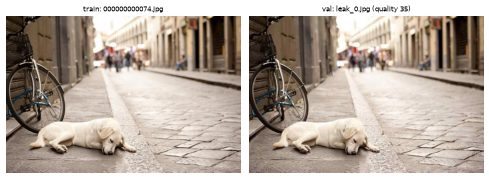

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
name, original_name = next(iter(planted.items()))
axes[0].imshow(PILImage.open(Path("coco128_leaky/images/train") / original_name))
axes[0].set_title(f"train: {original_name}", fontsize=9)
axes[1].imshow(PILImage.open(Path("coco128_leaky/images/val") / name))
axes[1].set_title(f"val: {name} (quality 35)", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

**What this shows.** One of the pairs side by side. A person can see these are the same photo, and so can the model, even though the files differ in size, name and compression.

## 10. The same thing from Python

Everything above is also available as three functions: `dc.load`, `dc.audit` and `dc.export`. Here they are in under ten lines.

In [26]:
import datacopilot as dc

ds = dc.load("coco128.dcp")  # read a dataset into memory
run = dc.audit(ds, fail_on=("warn",))  # run the checks; the verdict is in run.passed
print("passed:", run.passed, "| findings:", run.counts)
exported = dc.export(ds, "coco", "api_export")  # write another format
print("rows written:", exported.rows_written, "| lost:", exported.dropped or "nothing")

passed: False | findings: critical=0 warn=12 info=1
rows written: 1057 | lost: nothing


**What this shows.** A handful of lines give the same verdict as the command line: with `fail_on=("warn",)` the run does not pass, and the export reports its loss counts. In Python a
failed gate is recorded in `run.passed` instead of exiting the program.

## 11. What you learned

| Step | What you did | Take-away |
|---|---|---|
| Install | `datacopilot doctor` | One command tells you whether the install, the extras and the settings are healthy. |
| Real data | Downloaded COCO128, checked its checksum | Data is fetched at run time, never committed, and its fingerprint is on record. |
| Ingest | `ingest` made a `.dcp` with a version id | The same content always gets the same id, so you can name the exact data a model saw. |
| Audit | `audit` on the real photos | Real datasets have tiny boxes, overlapping labels and lopsided classes; warnings are prompts to look, not proof of errors. |
| Convert | COCO, VOC, CVAT, Label Studio, YOLO | Losses are counted, `--strict` refuses them, and reading the files back proves nothing else changed. |
| Classification | Cropped boxes into class folders | The same audit finds the class imbalance in an ImageFolder dataset. |
| CI | `--fail-on critical`, `warn`, `none` | The exit code (0 or 1) is all an automated build needs. |
| Look-alikes | DINOv2-small, nearest neighbours | A model finds similar pictures that byte comparison cannot. |
| Leakage | Planted three re-compressed copies | `--embedder dinov2_small --fail-on leakage` fails and names exactly those three; the clean data passes. |
| Python | `dc.load`, `dc.audit`, `dc.export` | The same power in a handful of lines. |

Next: the second notebook, `02_edge_cases.ipynb`, breaks the same real data in many ways to show what DataCopilot does when things go wrong.